# AI-Powered Predictive Bed Demand Forecasting for Albion Care Network

## Data Cleaning and Preprocessing

### Project Description Summary

**Project Title:** AI-Powered Hospital Bed Demand Forecasting for Albion Care Network

Albion Care Network is a leading UK private healthcare provider operating more than 39 hospitals across the country. The organisation faces significant challenges in managing hospital bed capacity due to fluctuating emergency admissions, elective surgeries, seasonal demand, and varying patient lengths of stay. Current bed planning relies heavily on historical averages and reactive decision-making, while operational data is fragmented across multiple hospital information systems, limiting the ability to anticipate future capacity constraints.

This project develops an AI-powered predictive analytics solution to transform bed management from a reactive process into a proactive, data-driven capability. By integrating admissions, bed occupancy, emergency arrivals, elective surgery schedules, and staffing data into a unified analytical platform, the solution forecasts hospital bed demand at hourly, daily, and weekly intervals across wards and bed types.

The project begins with exploratory data analysis (EDA) to identify historical trends, seasonal patterns, occupancy behaviour, and the relationships between admissions, discharges, staffing, and bed utilisation. Multiple forecasting approaches—including classical time-series methods and machine learning models—are then developed and evaluated to predict future admissions, occupancy levels, and capacity requirements.

The forecasting system supports operational decision-making by aligning staffing with anticipated demand, simulating scenarios such as influenza outbreaks, emergency admission surges, and delayed discharges, and providing planners with a centralised decision-support dashboard for monitoring future bed availability. A continuous feedback mechanism enables the models to be updated using actual occupancy outcomes, improving forecasting accuracy over time.

### Data Sources

The project integrates five core operational datasets:

* **Admissions & Discharges:** Captures patient inflow, discharge activity, admission characteristics, and length of stay, providing the primary drivers of bed demand.
* **Bed Inventory & Occupancy:** Records bed capacity, staffing availability, occupancy levels, and closed beds across hospital wards.
* **Emergency Department / Outpatient Arrivals:** Represents short-term unplanned demand that influences immediate bed requirements.
* **Elective Surgery Schedule:** Captures planned admissions and expected length of stay resulting from scheduled procedures.
* **Staffing & Resource Data:** Provides workforce availability and safe staffing indicators to evaluate whether forecasted bed demand can be operationally supported.

### Data Model Relationships

The datasets are integrated around common temporal and operational dimensions (date, time, ward, specialty, and bed type) to provide a comprehensive view of hospital capacity and patient flow.

* Admissions generate bed occupancy by introducing new patients into hospital wards.
* Discharges release occupied beds and directly influence future bed availability.
* Bed occupancy reflects the interaction between admissions, discharges, and available capacity.
* Emergency department arrivals create short-term fluctuations in demand and are key predictors of sudden occupancy increases.
* Elective surgery schedules introduce planned future admissions and expected bed utilisation based on anticipated lengths of stay.
* Staffing data provides operational context by indicating whether forecasted occupancy levels can be safely accommodated with available clinical resources.

Together, these relationships enable the development of predictive models that estimate future bed occupancy while accounting for both planned and unplanned patient demand, operational capacity, and workforce constraints.

### Project Objectives

The solution aims to:

* Explore historical trends and seasonal patterns in hospital admissions and bed occupancy.
* Forecast hourly, daily, and weekly bed demand across hospital wards and bed types.
* Improve workforce planning by aligning staffing levels with anticipated occupancy.
* Simulate operational scenarios such as flu outbreaks, discharge delays, and emergency admission surges.
* Deliver an interactive decision-support dashboard for proactive capacity management.
* Reduce elective procedure cancellations, patient transfers, and last-minute resource reallocations.
* Continuously improve forecasting performance through model monitoring and feedback using actual occupancy outcomes.

Overall, the project demonstrates how integrated healthcare data, predictive analytics, and artificial intelligence can enhance operational efficiency, improve patient flow, support clinical decision-making, and optimise hospital resource utilisation across Albion Care Network.

For a presentation, keep the scope concise and focused on the project lifecycle. Here's a slide-friendly version.


# Project Scope

### 1. Data Integration & Preparation

* Consolidate data from admissions, bed occupancy, emergency arrivals, elective surgery, and staffing systems.
* Clean, standardise, and preprocess data by handling missing values, duplicates, and inconsistencies.
* Align all datasets to a common hourly and daily time granularity.

---

### 2. Feature Engineering

* Create predictive features such as:

  * Lagged occupancy and admissions
  * Rolling averages
  * Length of stay (LOS)
  * Calendar and seasonal indicators
  * Emergency demand and elective surgery features

---


### 4. Forecasting & Predictive Modelling

* Develop and compare forecasting models, including:

  * SARIMAX
  * Random Forest
  * XGBoost and LightGBM
  * LSTM 
* Forecast hourly, daily, and weekly bed demand.
* Evaluate model performance using MAE, RMSE, and MAPE.

---

### 5. Scenario Simulation

* Assess the impact of:

  * Flu outbreaks
  * Emergency admission surges
  * Delayed discharges
  * Staffing shortages
* Support proactive capacity planning and resource allocation.

---

### 6. Decision Support Dashboard

* Develop an interactive dashboard displaying:

  * Current and forecasted bed occupancy
  * Admissions and discharges
  * Staffing levels
  * Capacity risk indicators
* Provide planners with actionable insights for operational decision-making.

---

### 7. Operational Integration & Continuous Improvement

* Integrate forecasts into hospital planning workflows.
* Implement automated alerts for potential bed shortages.
* Continuously monitor forecast accuracy and retrain models using new operational data.

---

# Expected Outcomes

* Improved bed demand forecasting accuracy.
* Reduced elective surgery cancellations.
* Better alignment of staffing with patient demand.
* Enhanced patient flow and resource utilisation.
* Proactive, data-driven hospital capacity planning.
* Increased operational efficiency and improved patient care.


# Import Required Libraries

In [1]:
import sys
# Import Python warnings module
# Used to control warning messages displayed during execution
import warnings
# Ignore non-critical warning messages to keep notebook output clean
warnings.filterwarnings("ignore")
# Then import all your libraries
import pandas as pd  # For data manipulation and analysis
import numpy as np   # For numerical operations
# Import type hints to define expected data types in functions
# Improves readability and helps with debugging (no impact on runtime)
from typing import Dict, Any, List, Tuple
import holidays  # Now this will work after installation

# Import data visualization libraries
import matplotlib.pyplot as plt  # For creating static visualizations
import seaborn as sns           # For enhanced statistical visualizations
import missingno as msno        # For visualisation of Missing Values
import gc  # Garbage collector for memory management
# Import preprocessing tools from scikit-learn for data transformation
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# Import Tables

In [ ]:


# ============================================================================
# STEP 1: Load the Admissions & Discharges Dataset
# ============================================================================
# Read the CSV file into a pandas DataFrame.
#
# header=None:
#     Indicates that the CSV file does not contain column headers.
#
# names=admissions_cols:
#     Assigns the predefined column names during import, ensuring the first
#     row is treated as data rather than column names.

admissions = pd.read_csv(
    "../data/raw/admissions_discharges.csv"
)

# ============================================================================
# STEP 2: Verify the Dataset
# ============================================================================
# Display the first few records and dataset structure to confirm that the
# admissions data has been loaded correctly.

print(admissions.head())

print("\nDataset Information")
print("=" * 70)

print(admissions.info())

FileNotFoundError: [Errno 2] No such file or directory: 'admissions_discharges.csv'

In [3]:
# ============================================================================
# STEP 1: Load the Bed Inventory & Occupancy Dataset
# ============================================================================
# Read the CSV file into a pandas DataFrame.
#
# header=None:
#     Indicates that the CSV file does not contain column headers.
#
# names=occupancy_cols:
#     Assigns the predefined column names during import, ensuring the first
#     row is treated as data rather than column headers.

occupancy = pd.read_csv(
    "bed_inventory_occupancy.csv"
)

# ============================================================================
# STEP 2: Verify the Dataset
# ============================================================================
# Display the first few records and dataset structure to confirm that the data
# has been imported successfully.

print(occupancy.head())

print("\nDataset Information")
print("=" * 70)

print(occupancy.info())

                  datetime hospital_id             ward  bed_type  total_beds  \
0  2024-01-06 18:00:00.000  HHN-LON-02  Cardiology Ward  Standard          18   
1  2024-01-06 19:00:00.000  HHN-LON-02  Cardiology Ward  Standard          18   
2  2024-01-07 15:00:00.000  HHN-LON-02  Cardiology Ward  Standard          18   
3  2024-01-07 16:00:00.000  HHN-LON-02  Cardiology Ward  Standard          18   
4  2024-01-07 18:00:00.000  HHN-LON-02  Cardiology Ward  Standard          18   

   staffed_beds  occupied_beds  closed_beds           occupancy_date  
0            18             18            0  2024-01-06 00:00:00.000  
1            18             18            0  2024-01-06 00:00:00.000  
2            18             18            0  2024-01-07 00:00:00.000  
3            18             18            0  2024-01-07 00:00:00.000  
4            18             18            0  2024-01-07 00:00:00.000  

Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 701760 entries, 0 to 701759

In [4]:

# ============================================================================
# STEP 1: Load the Emergency Department Dataset
# ============================================================================
# Read the CSV file into a pandas DataFrame.
#
# header=None:
#     Indicates that the CSV file does not contain column headers.
#
# names=ed_cols:
#     Assigns the predefined column names during import, ensuring the first
#     row is treated as data rather than column names.

ed = pd.read_csv(
    "ed_outpatient_arrivals.csv"
)

# ============================================================================
# STEP 2: Verify the Dataset
# ============================================================================
# Display the first few records and dataset structure to confirm that the
# Emergency Department data has been imported successfully.

print(ed.head())

print("\nDataset Information")
print("=" * 70)

print(ed.info())

  hospital_id   arrival_id         arrival_datetime triage_category  \
0  HHN-LON-01  ARR00000002  2024-01-01 22:06:00.000        Standard   
1  HHN-LON-01  ARR00000007  2024-01-01 11:00:00.000        Standard   
2  HHN-LON-01  ARR00000009  2024-01-01 16:09:00.000        Standard   
3  HHN-LON-01  ARR00000011  2024-01-01 12:10:00.000        Standard   
4  HHN-LON-01  ARR00000015  2024-01-01 19:25:00.000        Standard   

     arrival_mode          outcome  time_to_admission bed_requested  \
0  Self-Presented  Discharged Home                NaN            No   
1  Self-Presented  Discharged Home                NaN            No   
2  Self-Presented  Discharged Home                NaN            No   
3  Self-Presented  Discharged Home                NaN            No   
4  Self-Presented  Discharged Home                NaN            No   

              arrival_date  
0  2024-01-01 00:00:00.000  
1  2024-01-01 00:00:00.000  
2  2024-01-01 00:00:00.000  
3  2024-01-01 00:00:00.000  
4

In [5]:

# ============================================================================
# STEP 1: Load the Elective Surgery Dataset
# ============================================================================
# Read the CSV file into a pandas DataFrame.
surgery = pd.read_csv(
    "elective_surgery_schedule.csv"
    )

# ============================================================================
# STEP 2: Verify the Dataset
# ============================================================================
# Display the first few records and dataset structure to confirm that the data
# has been imported correctly.

print(surgery.head())
print(surgery.info())

  hospital_id   surgery_id             surgery_date    specialty  \
0  HHN-LON-01  SUR00000005  2024-01-03 00:00:00.000  Diagnostics   
1  HHN-LON-01  SUR00000033  2024-01-08 00:00:00.000  Diagnostics   
2  HHN-LON-01  SUR00000049  2024-01-10 00:00:00.000  Diagnostics   
3  HHN-LON-01  SUR00000081  2024-01-12 00:00:00.000  Diagnostics   
4  HHN-LON-01  SUR00000125  2024-01-18 00:00:00.000  Diagnostics   

  procedure_group bed_type_required surgery_status cancellation_reason  \
0    MRI Day Case          Standard      Completed       Not Cancelled   
1    MRI Day Case          Standard      Completed       Not Cancelled   
2    MRI Day Case          Standard      Completed       Not Cancelled   
3    MRI Day Case          Standard      Completed       Not Cancelled   
4    MRI Day Case          Standard      Completed       Not Cancelled   

   expected_los_clean  
0                 0.2  
1                 0.2  
2                 0.2  
3                 0.2  
4                 0.2  
<c

In [6]:
# ============================================================================
# STEP : Load the Hospital Reference Dataset
# ============================================================================
# Read the hospital reference CSV file into a pandas DataFrame.
#
# header=None:
#     Indicates that the CSV file does not contain column headers.
#
# names=hospital_cols:
#     Assigns the predefined column names during import, ensuring the first
#     row is treated as data rather than column names.

reference = pd.read_csv(
    "hospital_reference.csv"
   )

# ============================================================================
# STEP 2: Verify the Dataset
# ============================================================================
# Display the first few records and dataset structure to confirm that the
# hospital reference data has been imported successfully.

print(reference.head())

print("\nDataset Information")
print("=" * 70)

print(reference.info())

  hospital_id           hospital_name        city      tier  \
0  HHN-LON-01  Horizon London Central      London  Flagship   
1  HHN-LON-02       Horizon Riverside      London     Large   
2  HHN-MAN-01      Horizon Manchester  Manchester     Large   
3  HHN-BIR-01      Horizon Birmingham  Birmingham    Medium   
4  HHN-EDI-01       Horizon Edinburgh   Edinburgh    Medium   

  specialty_emphasis  total_bed_capacity  
0            General                 224  
1           Oncology                 152  
2       Orthopaedics                 164  
3         Cardiology                 126  
4            General                  94  

Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   hospital_id         5 non-null      str  
 1   hospital_name       5 non-null      str  
 2   city                5 non-null      str  
 3   tier         

In [7]:
# ============================================================================
# STEP 1: Load the Staffing & Resource Dataset
# ============================================================================
# Read the CSV file into a pandas DataFrame.

staffing = pd.read_csv(
    "staffing_resource.csv"
   )

# ============================================================================
# STEP 2: Verify the Dataset
# ============================================================================
# Display the first few records and dataset structure to confirm that the data
# has been imported successfully.

print(staffing.head())

print("\nDataset Information")
print("=" * 70)

print(staffing.info())

                      date hospital_id           ward        staff_role  \
0  2024-01-01 00:00:00.000  HHN-EDI-01  Oncology Ward  Registered Nurse   
1  2024-01-02 00:00:00.000  HHN-EDI-01  Oncology Ward  Registered Nurse   
2  2024-01-03 00:00:00.000  HHN-EDI-01  Oncology Ward  Registered Nurse   
3  2024-01-04 00:00:00.000  HHN-EDI-01  Oncology Ward  Registered Nurse   
4  2024-01-05 00:00:00.000  HHN-EDI-01  Oncology Ward  Registered Nurse   

   planned_staff  actual_staff safe_ratio_met  
0              2             2            Yes  
1              2             2            Yes  
2              2             2            Yes  
3              2             2            Yes  
4              2             2            Yes  

Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 116960 entries, 0 to 116959
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   date            116960 non-null  str  
 1   hosp

# All tables to one Dataframe

## ⚠️ Data Integration Fix

**Bug found:** the cell below used to run `pd.concat([admissions, occupancy, ed, surgery, reference, staffing])`.
`pd.concat` with no join keys stacks the six tables **on top of each other** (row-wise), even though they
have completely different columns and represent completely different things (one admission record, one
hourly bed-occupancy reading, one A&E arrival, one scheduled surgery, one hospital's static details, one
daily staffing entry). The result was a single 1.34M-row "Frankenstein" table where, for any given row,
only the columns from its *original* source table were populated — everything else was `NaN`.

That corrupted the `bed_demand` target two cells later: it grouped by a `date` column that (because of the
concat) only ever came from the *staffing* table, so `bed_demand` ended up counting how many stacked rows
happened to share a mostly-missing date — giving a nonsensical, near-constant value of **~1,184,076** for
almost every row (visible in `preprocessed_data.csv`) instead of a real bed-demand number.

**Fix:** merge the tables on their shared keys (`hospital_id`, `ward`, `date`) instead of stacking them.
Bed occupancy is kept as the base grain (it's the only table that directly measures beds in use), and the
event-level tables are aggregated to daily counts and joined onto it. `bed_demand` is then set directly
from `occupied_beds` — which is exactly what the later "target leakage" cell already assumed it would be.


In [8]:
# =============================================================================
# MERGE ALL TABLES INTO A SINGLE, CORRECT HOSPITAL-WARD-HOUR PANEL
# =============================================================================
# The six source tables have different grains:
#   - occupancy : one row per hospital + ward + bed_type + HOUR   (the real
#                 capacity/demand signal: total/staffed/occupied/closed beds)
#   - admissions: one row per PATIENT ADMISSION
#   - ed        : one row per A&E ARRIVAL
#   - surgery   : one row per SCHEDULED SURGERY
#   - staffing  : one row per hospital + ward + DAY
#   - reference : one row per HOSPITAL (static attributes)
#
# These must be MERGED on shared keys, not stacked with pd.concat, otherwise
# every row ends up with columns from only one source table and everything
# else NaN. We use bed occupancy as the base (it already IS the bed-demand
# signal) and left-join daily aggregates from the other feeds onto it.

# --- Step 1: Normalise the date key on every table -------------------------
occupancy["datetime"] = pd.to_datetime(occupancy["datetime"])
occupancy["date"] = occupancy["datetime"].dt.date

ed["date"] = pd.to_datetime(ed["arrival_date"], errors="coerce").dt.date
surgery["date"] = pd.to_datetime(surgery["surgery_date"], errors="coerce").dt.date
staffing["date"] = pd.to_datetime(staffing["date"], errors="coerce").dt.date

# --- Step 1b: Check whether admissions dates are usable ---------------------
# DATA QUALITY ISSUE FOUND: admission_datetime / admission_date in
# admissions_discharges.csv only contain minute:second values (e.g.
# "45:00.0") - the date and hour were lost, almost certainly because the
# source file was re-saved through Excel with a time-only cell format
# applied to a full datetime column. Every admission ends up looking like
# it happened on the same non-existent "date". We detect this automatically
# instead of silently joining on a broken key.

parsed_admission_date = pd.to_datetime(admissions["admission_date"], errors="coerce")
admissions_date_usable = parsed_admission_date.dt.date.nunique(dropna=True) > 1

if not admissions_date_usable:
    print("=" * 80)
    print("WARNING: admissions_discharges.csv has corrupted timestamps")
    print("=" * 80)
    print(
        "admission_datetime / admission_date only contain minute:second\n"
        "values with no date or hour information, so admissions cannot be\n"
        "aligned to a specific day or hour. Falling back to a hospital-level\n"
        "(not date-level) admissions summary so this information isn't lost\n"
        "entirely. Fix this at the source - re-export admissions_discharges.csv\n"
        "with full, uncorrupted timestamps - to recover true daily admission\n"
        "counts, which the project description lists as a primary driver of\n"
        "bed demand."
    )
    daily_admissions = (
        admissions.groupby("hospital_id")
        .size()
        .reset_index(name="hospital_total_admissions")
    )
    admissions_join_keys = ["hospital_id"]
else:
    admissions["date"] = parsed_admission_date.dt.date
    daily_admissions = (
        admissions.groupby(["hospital_id", "ward", "date"])
        .size()
        .reset_index(name="daily_admissions")
    )
    admissions_join_keys = ["hospital_id", "ward", "date"]

# --- Step 2: Aggregate the remaining event-level tables to hospital/day ----
# (ED arrivals and surgeries don't carry a ward, so aggregate at hospital +
# day level; staffing carries a ward, like occupancy)

daily_ed = (
    ed.groupby(["hospital_id", "date"])
    .size()
    .reset_index(name="daily_ed_arrivals")
)

daily_surgery = (
    surgery.groupby(["hospital_id", "date"])
    .size()
    .reset_index(name="daily_elective_admissions")
)

daily_staffing = (
    staffing.groupby(["hospital_id", "ward", "date"])
    .agg(planned_staff=("planned_staff", "sum"),
         actual_staff=("actual_staff", "sum"))
    .reset_index()
)

# --- Step 3: Build the panel, using occupancy (the real demand signal) -----
# as the base grain and left-joining everything else onto it -----------------

df = occupancy.merge(
    daily_admissions, on=admissions_join_keys, how="left"
)
df = df.merge(
    daily_ed, on=["hospital_id", "date"], how="left"
)
df = df.merge(
    daily_surgery, on=["hospital_id", "date"], how="left"
)
df = df.merge(
    daily_staffing, on=["hospital_id", "ward", "date"], how="left"
)
df = df.merge(
    reference, on="hospital_id", how="left"
)

# --- Step 4: Zero-fill counts -----------------------------------------------
# A ward/day with no matching admissions, ED arrivals, or surgeries genuinely
# had zero of that activity - this is NOT missing data, so fillna(0) here is
# correct (unlike a blanket median/mode fill later in the notebook).

for col in ["daily_admissions", "daily_ed_arrivals", "daily_elective_admissions"]:
    if col in df.columns:
        df[col] = df[col].fillna(0)

print("=" * 80)
print("MERGED DATASET SHAPE:", df.shape)
print("=" * 80)

df.head()

admission_datetime / admission_date only contain minute:second
values with no date or hour information, so admissions cannot be
aligned to a specific day or hour. Falling back to a hospital-level
(not date-level) admissions summary so this information isn't lost
entirely. Fix this at the source - re-export admissions_discharges.csv
with full, uncorrupted timestamps - to recover true daily admission
counts, which the project description lists as a primary driver of
bed demand.


MERGED DATASET SHAPE: (701760, 20)


,datetime,hospital_id,ward,bed_type,total_beds,staffed_beds,occupied_beds,closed_beds,occupancy_date,date,hospital_total_admissions,daily_ed_arrivals,daily_elective_admissions,planned_staff,actual_staff,hospital_name,city,tier,specialty_emphasis,total_bed_capacity
0,2024-01-06 18:00:00,HHN-LON-02,Cardiology Ward,Standard,18,18,18,0,2024-01-06 00:00:00.000,2024-01-06,26464,83,0.0,9,9,Horizon Riverside,London,Large,Oncology,152
1,2024-01-06 19:00:00,HHN-LON-02,Cardiology Ward,Standard,18,18,18,0,2024-01-06 00:00:00.000,2024-01-06,26464,83,0.0,9,9,Horizon Riverside,London,Large,Oncology,152
2,2024-01-07 15:00:00,HHN-LON-02,Cardiology Ward,Standard,18,18,18,0,2024-01-07 00:00:00.000,2024-01-07,26464,136,0.0,9,9,Horizon Riverside,London,Large,Oncology,152
3,2024-01-07 16:00:00,HHN-LON-02,Cardiology Ward,Standard,18,18,18,0,2024-01-07 00:00:00.000,2024-01-07,26464,136,0.0,9,9,Horizon Riverside,London,Large,Oncology,152
4,2024-01-07 18:00:00,HHN-LON-02,Cardiology Ward,Standard,18,18,18,0,2024-01-07 00:00:00.000,2024-01-07,26464,136,0.0,9,9,Horizon Riverside,London,Large,Oncology,152


In [9]:
# Display comprehensive information about the DataFrame including data types, non-null counts, and memory usage
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 701760 entries, 0 to 701759
Data columns (total 20 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   datetime                   701760 non-null  datetime64[us]
 1   hospital_id                701760 non-null  str           
 2   ward                       701760 non-null  str           
 3   bed_type                   701760 non-null  str           
 4   total_beds                 701760 non-null  int64         
 5   staffed_beds               701760 non-null  int64         
 6   occupied_beds              701760 non-null  int64         
 7   closed_beds                701760 non-null  int64         
 8   occupancy_date             701760 non-null  str           
 9   date                       701760 non-null  object        
 10  hospital_total_admissions  701760 non-null  int64         
 11  daily_ed_arrivals          701760 non-null  int64         
 12 

In [10]:
# Check for missing values in each column of the dataframe
df.isnull().sum()

datetime                     0
hospital_id                  0
ward                         0
bed_type                     0
total_beds                   0
staffed_beds                 0
occupied_beds                0
closed_beds                  0
occupancy_date               0
date                         0
hospital_total_admissions    0
daily_ed_arrivals            0
daily_elective_admissions    0
planned_staff                0
actual_staff                 0
hospital_name                0
city                         0
tier                         0
specialty_emphasis           0
total_bed_capacity           0
dtype: int64

# Data Cleaning and Preprocessing

## Remove Unwanted Columns

In [11]:
# =============================================================================
# Drop Unwanted Columns
# =============================================================================

def drop_unwanted_columns(dataframe: pd.DataFrame) -> pd.DataFrame:
    """
    Removes unwanted identifier columns from the dataframe if they exist.

    Args:
        dataframe (pd.DataFrame): Input dataframe.

    Returns:
        pd.DataFrame: Cleaned dataframe.
    """

    # List of columns to remove
    columns_to_drop = [
        "hospital_id",
        "patient_id",
        "admission_id",
        "arrival_id",
         'surgery_id',
    ]

    # Keep only columns that exist in the dataframe
    existing_columns = [
        col for col in columns_to_drop
        if col in dataframe.columns
    ]

    # Drop the columns if they exist
    if existing_columns:
        dataframe = dataframe.drop(
            columns=existing_columns
        )

    return dataframe


# Apply the function
df = drop_unwanted_columns(df)

# Check the remaining columns
print(df.columns)

Index(['datetime', 'ward', 'bed_type', 'total_beds', 'staffed_beds',
       'occupied_beds', 'closed_beds', 'occupancy_date', 'date',
       'hospital_total_admissions', 'daily_ed_arrivals',
       'daily_elective_admissions', 'planned_staff', 'actual_staff',
       'hospital_name', 'city', 'tier', 'specialty_emphasis',
       'total_bed_capacity'],
      dtype='str')


# Investigating and Handling Missing Values

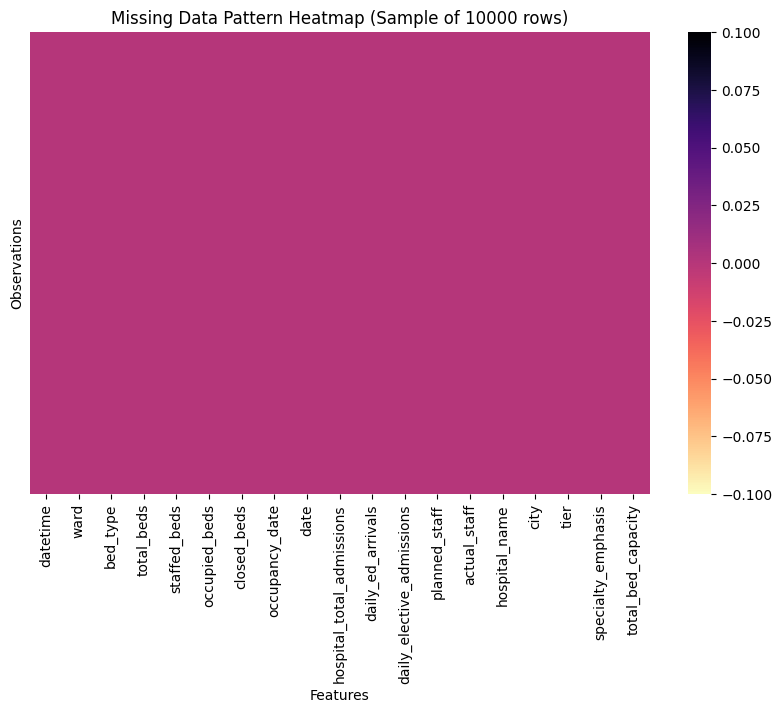

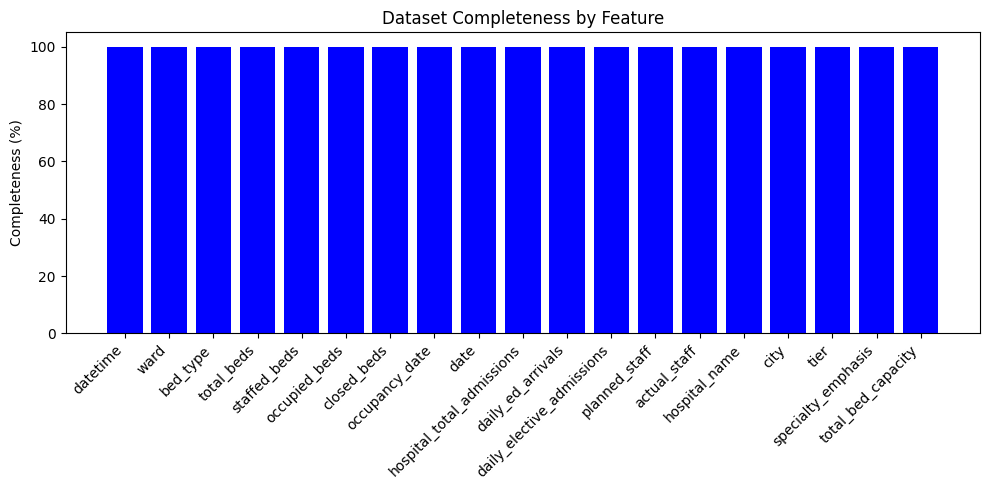


MISSING DATA REPORT
Dataset shape: (701760, 19)
Total missing values: 0
Overall missing percentage: 0.00%

Missing percentage by feature:
No missing values found!


In [12]:
# ANALYZE MISSING DATA PATTERN (MEMORY-EFFICIENT VERSION)
# ============================================================================
# Purpose:
# Show where missing values occur across rows and columns for large datasets.
# Memory-efficient approach using sampling and chunking.

# Sample the dataset to reduce memory usage for visualization
sample_size = min(10000, len(df))  # Use max 10,000 rows for heatmap
df_sample = df.sample(n=sample_size, random_state=42)

plt.figure(figsize=(10, 6))

# Create heatmap with sampled data
sns.heatmap(
    df_sample.isnull(),
    cbar=True,          # Display colour scale legend
    cmap="magma_r",     # Colour scheme for missing value visibility
    yticklabels=False   # Hide y-axis labels to improve performance
)

plt.title(f"Missing Data Pattern Heatmap (Sample of {sample_size} rows)")
plt.xlabel("Features")
plt.ylabel("Observations")

plt.show()


# ============================================================================
# STEP 3: COLUMN COMPLETENESS VISUALISATION (MEMORY-EFFICIENT)
# ============================================================================
# Purpose:
# Display the proportion of available data in each feature.
# Calculate completeness without loading entire dataset into memory.

plt.figure(figsize=(10, 5))

# Calculate missing counts more efficiently
missing_counts = df.isnull().sum()
completeness = ((len(df) - missing_counts) / len(df)) * 100

# Create bar plot manually instead of using msno.bar for better memory control
plt.bar(range(len(completeness)), completeness.values, color="blue")
plt.xticks(range(len(completeness)), completeness.index, rotation=45, ha='right')
plt.ylabel("Completeness (%)")
plt.title("Dataset Completeness by Feature")
plt.tight_layout()

plt.show()


# ============================================================================
# STEP 4: MISSING DATA REPORT (MEMORY-EFFICIENT)
# ============================================================================
# Purpose:
# Provide a final summary using efficient calculations.

# Calculate missing statistics efficiently
total_missing = df.isnull().sum().sum()
missing_percentage = ((df.isnull().sum() / len(df)) * 100).sort_values(ascending=False)

print("\nMISSING DATA REPORT")
print("=" * 50)
print(f"Dataset shape: {df.shape}")
print(f"Total missing values: {total_missing}")
print(f"Overall missing percentage: {(total_missing / (df.shape[0] * df.shape[1])) * 100:.2f}%")

print("\nMissing percentage by feature:")
features_with_missing = missing_percentage[missing_percentage > 0]
if len(features_with_missing) > 0:
    print(features_with_missing)
else:
    print("No missing values found!")

# ============================================================================
# MEMORY-EFFICIENT IMPROVEMENTS:
# 1. Sample dataset for heatmap visualization (max 10,000 rows)
# 2. Remove y-axis labels from heatmap to reduce memory usage
# 3. Replace msno.bar() with manual bar plot for better memory control
# 4. Calculate statistics directly without creating intermediate large arrays
# 5. Added dataset shape information for context
# ============================================================================

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 701760 entries, 0 to 701759
Data columns (total 19 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   datetime                   701760 non-null  datetime64[us]
 1   ward                       701760 non-null  str           
 2   bed_type                   701760 non-null  str           
 3   total_beds                 701760 non-null  int64         
 4   staffed_beds               701760 non-null  int64         
 5   occupied_beds              701760 non-null  int64         
 6   closed_beds                701760 non-null  int64         
 7   occupancy_date             701760 non-null  str           
 8   date                       701760 non-null  object        
 9   hospital_total_admissions  701760 non-null  int64         
 10  daily_ed_arrivals          701760 non-null  int64         
 11  daily_elective_admissions  701760 non-null  float64       
 12 

### Handline Missing Values 

In [14]:
# =============================================================================
# HOSPITAL BED DEMAND FORECASTING
# MISSING VALUE HANDLING PIPELINE
# =============================================================================
#
# OBJECTIVE:
# ----------
# Prepare the hospital dataset for predictive modelling by resolving missing
# information without removing important forecasting variables.
#
# The dataset contains:
#
# 1. Datetime variables
#    - Admission dates
#    - Discharge dates
#    - Occupancy dates
#    - Surgery dates
#
# 2. Numerical variables
#    - Bed capacity
#    - Staffing levels
#    - Length of stay
#    - Demand values
#    - Lag features
#
# 3. Categorical variables
#    - Admission type
#    - Ward
#    - Specialty
#    - Hospital information
#
#
# IMPUTATION STRATEGY:
# --------------------
#
# DATETIME VARIABLES:
# -------------------
# Missing dates are handled using forward-fill and backward-fill.
#
# Reason:
# Hospital records are sequential. Previous or next observations provide
# realistic timestamps without destroying the time-series structure required
# by forecasting models such as LSTM.
#
#
# NUMERICAL VARIABLES:
# --------------------
#
# Operational variables:
#     Missing values represent absence of activity.
#
#     Example:
#       closed_beds = 0
#       planned_staff = 0
#
#     Therefore, missing values are replaced with zero.
#
#
# Continuous variables:
#     Missing values are replaced with the median.
#
#     Reason:
#       The median is less affected by extreme values and outliers.
#
#
# CATEGORICAL VARIABLES:
# ----------------------
#
# Variables with meaningful missing states:
#     Replace with "Unknown".
#
# Example:
#     Missing surgery_status may mean no surgery was planned.
#
#
# Normal categorical variables:
#     Replace with mode (most frequent category).
#
# =============================================================================



# =============================================================================
# IMPORT REQUIRED LIBRARIES
# ============================================================================


# =============================================================================
# STEP 1: IDENTIFY DATETIME VARIABLES
# =============================================================================
#
# The dataframe contains several date columns.
#
# These variables are important because they are used later to create:
#
# - Hour features
# - Daily trends
# - Seasonal features
# - Lag variables
#
# Therefore, they must NOT be removed.
#
# =============================================================================


datetime_features = [

    "admission_datetime",

    "discharge_datetime",

    "admission_date",

    "datetime",

    "occupancy_date",

    "arrival_datetime",

    "arrival_date",

    "surgery_date"

]


# Keep only datetime columns that exist in dataframe

datetime_features = [

    col for col in datetime_features

    if col in df.columns

]



# =============================================================================
# STEP 2: IDENTIFY NUMERICAL AND CATEGORICAL VARIABLES
# =============================================================================
#
# Numerical variables:
#     Used directly by machine learning models.
#
# Categorical variables:
#     Require encoding before modelling.
#
# =============================================================================


numerical_features = df.select_dtypes(

    include=[

        "float64",

        "float32",

        "int64",

        "int32"

    ]

).columns



categorical_features = df.select_dtypes(

    include=[

        "object",

        "category"

    ]

).columns



print("="*80)

print("VARIABLE TYPES IDENTIFIED")

print("="*80)



print("Datetime Variables:")

print(datetime_features)



print("\nNumerical Variables:")

print(list(numerical_features))



print("\nCategorical Variables:")

print(list(categorical_features))



# =============================================================================
# STEP 3: HANDLE MISSING DATETIME INFORMATION
# =============================================================================
#
# Convert all date variables into pandas datetime format.
#
# errors='coerce':
#     Invalid dates are converted into missing datetime values (NaT).
#
# Missing dates are then replaced using:
#
# Forward fill:
#     Uses the previous valid timestamp.
#
# Backward fill:
#     Uses the next valid timestamp.
#
# This preserves chronological ordering.
#
# =============================================================================


for col in datetime_features:


    # Convert variable into datetime format

    df[col] = pd.to_datetime(

        df[col],

        errors="coerce"

    )


    # Fill missing timestamps

    df[col] = (

        df[col]

        .ffill()

        .bfill()

    )


    gc.collect()



# =============================================================================
# STEP 4: DEFINE ZERO IMPUTATION VARIABLES
# =============================================================================
#
# These variables represent operational absence.
#
# Missing values mean that the activity did not occur.
#
# Examples:
#
# closed_beds:
#     No beds were closed.
#
# planned_staff:
#     No staff planned.
#
# bed_demand_change:
#     No change in demand.
#
# =============================================================================


zero_imputation_features = [

    "closed_beds",

    "planned_staff",

    "actual_staff",

    "bed_demand_change_1",

    "bed_demand_change_7"

]



# =============================================================================
# STEP 5: IMPUTE NUMERICAL VARIABLES
# =============================================================================
#
# Two approaches are used:
#
# 1. Zero replacement
#    For operational activity variables.
#
# 2. Median replacement
#    For continuous measurements.
#
# =============================================================================


for col in numerical_features:


    if col in zero_imputation_features:


        # Replace missing operational values with zero

        df[col] = df[col].fillna(0)



    else:


        # Replace missing continuous values with median

        median_value = df[col].median()


        df[col] = df[col].fillna(

            median_value

        )


    gc.collect()



# =============================================================================
# STEP 6: DEFINE CATEGORICAL VARIABLES USING UNKNOWN
# =============================================================================
#
# Some missing categories contain information.
#
# Example:
#
# surgery_status missing:
#     Could indicate that no surgery occurred.
#
# Therefore, "Unknown" is used instead of replacing with the mode.
#
# =============================================================================


unknown_features = [

    "procedure_group",

    "bed_type_required",

    "surgery_status",

    "cancellation_reason",

    "safe_ratio_met",

    "staff_role"

]



# =============================================================================
# STEP 7: IMPUTE CATEGORICAL VARIABLES
# =============================================================================
#
# For normal categorical variables:
#
# Missing values are replaced with the most frequent category.
#
# For operational categories:
#
# Missing values are replaced with "Unknown".
#
# Finally, variables are converted back to category type to reduce memory.
#
# =============================================================================


for col in categorical_features:


    # Convert to object for safe replacement

    df[col] = df[col].astype("object")



    if col in unknown_features:


        df[col] = df[col].fillna(

            "Unknown"

        )


    else:


        # Calculate most common category

        mode_value = df[col].mode()



        if len(mode_value) > 0:


            df[col] = df[col].fillna(

                mode_value[0]

            )


        else:


            df[col] = df[col].fillna(

                "Unknown"

            )



    # Convert back to category

    df[col] = df[col].astype("category")


    gc.collect()



# =============================================================================
# STEP 8: CHECK REMAINING MISSING VALUES
# =============================================================================
#
# This validates that the dataset is complete before modelling.
#
# =============================================================================


missing_values = (

    df.isnull()

    .sum()

)



missing_values = missing_values[

    missing_values > 0

]



print("="*80)

print("MISSING VALUE CHECK")

print("="*80)



if len(missing_values) == 0:

    print("SUCCESS: No missing values remaining")


else:

    print(missing_values)



# =============================================================================
# STEP 9: FINAL DATASET SUMMARY
# =============================================================================
#
# The cleaned dataframe is now ready for:
#
# 1. Encoding categorical variables
# 2. Feature scaling
# 3. Train/test splitting
# 4. LSTM sequence preparation
#
# =============================================================================


print("="*80)

print("FINAL CLEAN DATASET")

print("="*80)



print("Shape:")

print(df.shape)



print("\nVariable Types:")

print(df.dtypes.value_counts())



print("\nMemory Usage:")

print(

    f"{df.memory_usage(deep=True).sum()/1024**2:.2f} MB"

)

VARIABLE TYPES IDENTIFIED
Datetime Variables:
['datetime', 'occupancy_date']

Numerical Variables:
['total_beds', 'staffed_beds', 'occupied_beds', 'closed_beds', 'hospital_total_admissions', 'daily_ed_arrivals', 'daily_elective_admissions', 'planned_staff', 'actual_staff', 'total_bed_capacity']

Categorical Variables:
['ward', 'bed_type', 'occupancy_date', 'date', 'hospital_name', 'city', 'tier', 'specialty_emphasis']


MISSING VALUE CHECK
SUCCESS: No missing values remaining
FINAL CLEAN DATASET
Shape:
(701760, 19)

Variable Types:
int64             9
datetime64[us]    1
category          1
category          1
category          1
category          1
float64           1
category          1
category          1
category          1
category          1
Name: count, dtype: int64

Memory Usage:
65.62 MB


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 701760 entries, 0 to 701759
Data columns (total 19 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   datetime                   701760 non-null  datetime64[us]
 1   ward                       701760 non-null  category      
 2   bed_type                   701760 non-null  category      
 3   total_beds                 701760 non-null  int64         
 4   staffed_beds               701760 non-null  int64         
 5   occupied_beds              701760 non-null  int64         
 6   closed_beds                701760 non-null  int64         
 7   occupancy_date             701760 non-null  category      
 8   date                       701760 non-null  category      
 9   hospital_total_admissions  701760 non-null  int64         
 10  daily_ed_arrivals          701760 non-null  int64         
 11  daily_elective_admissions  701760 non-null  float64       
 12 

# Investigating and Handling Duplicated Variables

In [16]:
# =============================================================================
# AUTOMATED DUPLICATE DETECTION AND REMOVAL PIPELINE
# =============================================================================
# Purpose:
# This pipeline automatically:
# 1. Detects duplicate rows in the dataset
# 2. Displays duplicate records for review
# 3. Removes duplicate observations
# 4. Resets the dataframe index
# 5. Verifies that duplicates have been removed
#
# Note:
# ID variables have already been removed, therefore duplicate detection
# is performed using all remaining dataframe columns.
# =============================================================================

# =============================================================================
# Create Duplicate Removal Function
# =============================================================================

def remove_duplicates(dataframe: pd.DataFrame) -> pd.DataFrame:
    """
    Detects and removes duplicate rows from a dataframe.

    Parameters:
    -----------
    dataframe : pd.DataFrame
        Input dataset containing hospital operational data.

    Returns:
    --------
    pd.DataFrame
        Cleaned dataframe with duplicate records removed.
    """


    # =========================================================================
    # Step 1: Count Duplicate Records
    # =========================================================================
    # Identify rows where all column values are identical.

    duplicate_count = dataframe.duplicated().sum()


    print("=" * 80)
    print("DUPLICATE RECORDS BEFORE REMOVAL")
    print("=" * 80)

    print(
        f"Number of duplicate rows: {duplicate_count}"
    )



    # =========================================================================
    # Step 2: Display Duplicate Records
    # =========================================================================
    # Show sample duplicate rows before removing them.
    # This allows quality checking before data cleaning.

    if duplicate_count > 0:

        print("=" * 80)
        print("SAMPLE DUPLICATE RECORDS")
        print("=" * 80)

        print(

            dataframe[
                dataframe.duplicated()
            ]
            .head()

        )



    # =========================================================================
    # Step 3: Remove Duplicate Rows
    # =========================================================================
    # Keep the first occurrence of each record and remove subsequent copies.

    dataframe = dataframe.drop_duplicates(
        keep="first"
    )



    # =========================================================================
    # Step 4: Reset Index
    # =========================================================================
    # Removing rows creates gaps in the dataframe index.
    # Resetting creates a clean sequential index.

    dataframe = dataframe.reset_index(
        drop=True
    )



    # =========================================================================
    # Step 5: Verify Duplicate Removal
    # =========================================================================

    remaining_duplicates = (
        dataframe
        .duplicated()
        .sum()
    )


    print("=" * 80)
    print("DUPLICATE RECORDS AFTER REMOVAL")
    print("=" * 80)

    print(
        f"Remaining duplicate rows: {remaining_duplicates}"
    )



    # =========================================================================
    # Step 6: Display Dataset Information
    # =========================================================================

    print("=" * 80)
    print("DATASET SIZE AFTER CLEANING")
    print("=" * 80)

    print(
        dataframe.shape
    )


    return dataframe



# =============================================================================
# Apply Duplicate Removal Function
# =============================================================================

df = remove_duplicates(df)



# =============================================================================
# Display Clean Dataset
# =============================================================================

print("=" * 80)
print("CLEANED DATASET PREVIEW")
print("=" * 80)

print(
    df.head()
)

DUPLICATE RECORDS BEFORE REMOVAL
Number of duplicate rows: 0


DUPLICATE RECORDS AFTER REMOVAL
Remaining duplicate rows: 0
DATASET SIZE AFTER CLEANING
(701760, 19)
CLEANED DATASET PREVIEW
             datetime             ward  bed_type  total_beds  staffed_beds  \
0 2024-01-06 18:00:00  Cardiology Ward  Standard          18            18   
1 2024-01-06 19:00:00  Cardiology Ward  Standard          18            18   
2 2024-01-07 15:00:00  Cardiology Ward  Standard          18            18   
3 2024-01-07 16:00:00  Cardiology Ward  Standard          18            18   
4 2024-01-07 18:00:00  Cardiology Ward  Standard          18            18   

   occupied_beds  closed_beds occupancy_date        date  \
0             18            0     2024-01-06  2024-01-06   
1             18            0     2024-01-06  2024-01-06   
2             18            0     2024-01-07  2024-01-07   
3             18            0     2024-01-07  2024-01-07   
4             18            0     2024-01-07  2024-01-07   

   hospital_total_admissions  daily_ed_arriva

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 701760 entries, 0 to 701759
Data columns (total 19 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   datetime                   701760 non-null  datetime64[us]
 1   ward                       701760 non-null  category      
 2   bed_type                   701760 non-null  category      
 3   total_beds                 701760 non-null  int64         
 4   staffed_beds               701760 non-null  int64         
 5   occupied_beds              701760 non-null  int64         
 6   closed_beds                701760 non-null  int64         
 7   occupancy_date             701760 non-null  category      
 8   date                       701760 non-null  category      
 9   hospital_total_admissions  701760 non-null  int64         
 10  daily_ed_arrivals          701760 non-null  int64         
 11  daily_elective_admissions  701760 non-null  float64       
 12 

# Feature Engineering

### Create the Target Variable (bed_demand)

In [18]:
# =============================================================================
# CREATE BED DEMAND TARGET VARIABLE
# =============================================================================
#
# PURPOSE:
# --------
# Create the target variable used for hospital bed demand forecasting.
#
# The target variable:
#
#       bed_demand
#
# represents the number of beds occupied by patients.
#
# =============================================================================
#
# NOTE (fix):
# -----------
# Previously this cell tried to derive bed_demand from a "date" column that
# only existed because of the pd.concat bug, and it counted stacked rows
# instead of actual bed occupancy - producing a near-constant, meaningless
# value (~1,184,076) for almost every row.
#
# Now that df is built from a proper merge (base grain = hospital + ward +
# hour, from the bed occupancy table), occupied_beds is already the correct,
# direct measurement of bed demand for every row, so we use it directly.
# This also matches the "target leakage" step later in the notebook, which
# already assumed bed_demand was created from occupied_beds and therefore
# drops occupied_beds from the feature set.
# =============================================================================

print("=" * 80)
print("AVAILABLE DATAFRAME COLUMNS")
print("=" * 80)
print(df.columns.tolist())

if "occupied_beds" not in df.columns:
    raise ValueError(
        "occupied_beds column is missing - check the merge step that builds df."
    )

df["bed_demand"] = df["occupied_beds"]

# =============================================================================
# STEP 2: VERIFY TARGET VARIABLE
# =============================================================================

print("=" * 80)
print("BED DEMAND TARGET CREATED")
print("=" * 80)

print(df["bed_demand"].head())

# =============================================================================
# STEP 3: SUMMARY STATISTICS OF TARGET
# =============================================================================

print("=" * 80)
print("BED DEMAND SUMMARY STATISTICS")
print("=" * 80)

print(df["bed_demand"].describe())

# =============================================================================
# STEP 4: FINAL DATASET CHECK
# =============================================================================

print("=" * 80)
print("FINAL DATASET INFORMATION")
print("=" * 80)

print("Dataset Shape:", df.shape)

print("\nFinal Columns:")
print(df.columns.tolist())

print("\nDataset Preview:")
print(df.head())

AVAILABLE DATAFRAME COLUMNS
['datetime', 'ward', 'bed_type', 'total_beds', 'staffed_beds', 'occupied_beds', 'closed_beds', 'occupancy_date', 'date', 'hospital_total_admissions', 'daily_ed_arrivals', 'daily_elective_admissions', 'planned_staff', 'actual_staff', 'hospital_name', 'city', 'tier', 'specialty_emphasis', 'total_bed_capacity']
BED DEMAND TARGET CREATED
0    18
1    18
2    18
3    18
4    18
Name: bed_demand, dtype: int64
BED DEMAND SUMMARY STATISTICS
count    701760.000000
mean         14.092644
std           8.772003
min           0.000000
25%           9.000000
50%          13.000000
75%          19.000000
max          46.000000
Name: bed_demand, dtype: float64
FINAL DATASET INFORMATION
Dataset Shape: (701760, 20)

Final Columns:
['datetime', 'ward', 'bed_type', 'total_beds', 'staffed_beds', 'occupied_beds', 'closed_beds', 'occupancy_date', 'date', 'hospital_total_admissions', 'daily_ed_arrivals', 'daily_elective_admissions', 'planned_staff', 'actual_staff', 'hospital_name'

### Create Lag Variables

In [19]:
# =============================================================================
# HOSPITAL BED DEMAND FORECASTING - LAG FEATURE ENGINEERING PIPELINE
# =============================================================================
#
# PURPOSE:
# --------
# Create historical demand features from the target variable:
#
#                         bed_demand
#
# Lag features are important for time-series forecasting because hospital
# demand usually depends on previous demand patterns.
#
# Examples:
#
# bed_demand_lag_1:
#       Previous day's bed demand
#
# bed_demand_lag_7:
#       Bed demand from the previous week
#
# bed_demand_lag_30:
#       Bed demand from the previous month
#
# Rolling averages:
#       Capture demand trends and smooth short-term fluctuations.
#
# These features will be used as input variables for LSTM forecasting.
#
# =============================================================================


# Import garbage collection to manage memory
# This is useful because the dataset contains over 70,000 observations.

import gc



# =============================================================================
# STEP 1: VERIFY TARGET VARIABLE EXISTS
# =============================================================================
#
# Lag features are generated from the target variable:
#
#              bed_demand
#
# If this variable does not exist, lag creation cannot continue.
#
# =============================================================================


if "bed_demand" not in df.columns:


    raise ValueError(

        "bed_demand target variable is missing. Create it before generating lags."

    )



print("="*80)

print("BED DEMAND LAG FEATURE ENGINEERING")

print("="*80)



# =============================================================================
# STEP 2: IDENTIFY TIME VARIABLE
# =============================================================================
#
# Time-series models require observations to be arranged chronologically.
#
# The pipeline checks available date variables and selects the first available.
#
# Priority:
#
# 1. date
# 2. datetime
# 3. admission_date
# 4. occupancy_date
#
# =============================================================================


date_column = None



possible_date_columns = [

    "date",

    "datetime",

    "admission_date",

    "occupancy_date"

]



for col in possible_date_columns:


    if col in df.columns:


        date_column = col

        break



# =============================================================================
# STEP 3: SORT DATA BY TIME
# =============================================================================
#
# Lag features depend on the correct sequence of observations.
#
# Example:
#
# Row 1 = January 1 demand
# Row 2 = January 2 demand
#
# If the data is not sorted, the lag values will be incorrect.
#
# =============================================================================


if date_column is not None:


    # Convert date variable into datetime format

    df[date_column] = pd.to_datetime(

        df[date_column],

        errors="coerce"

    )


    # Sort observations chronologically

    df = df.sort_values(

        by=date_column

    ).reset_index(drop=True)



    print(

        f"Dataset sorted using {date_column}"

    )


else:


    print(

        "No date variable found. Using current dataframe order."

    )



# =============================================================================
# STEP 4: CREATE LAG FEATURES
# =============================================================================
#
# Lag features shift historical demand values forward.
#
# Formula:
#
#       lag_n = bed_demand from n previous periods
#
#
# Examples:
#
# lag_1:
#   Uses yesterday's demand
#
# lag_7:
#   Uses demand from 7 days ago
#
# lag_30:
#   Uses demand from 30 days ago
#
# =============================================================================


lag_periods = [

    1,

    7,

    14,

    30

]



for lag in lag_periods:


    # Create shifted demand variable

    df[f"bed_demand_lag_{lag}"] = (

        df["bed_demand"]

        .shift(lag)

    )


    # Release unused memory

    gc.collect()



# =============================================================================
# STEP 5: CREATE ROLLING AVERAGE FEATURES
# =============================================================================
#
# Rolling averages capture the recent demand trend.
#
# Example:
#
# rolling_7:
#     Average demand over the previous 7 periods
#
#
# IMPORTANT:
#
# shift(1) is applied before rolling.
#
# This prevents data leakage because the model should not see
# the current day's demand when predicting demand.
#
# =============================================================================


rolling_periods = [

    7,

    14,

    30

]



for window in rolling_periods:


    df[f"bed_demand_rolling_{window}"] = (

        df["bed_demand"]

        .shift(1)

        .rolling(

            window=window

        )

        .mean()

    )


    gc.collect()



# =============================================================================
# STEP 6: CREATE DEMAND CHANGE FEATURES
# =============================================================================
#
# These variables measure how demand changes over time.
#
# They help the model identify:
#
# - Increasing pressure on beds
# - Sudden increases in demand
# - Demand reductions
#
# =============================================================================


# Daily change in demand

df["bed_demand_change_1"] = (

    df["bed_demand"]

    -

    df["bed_demand_lag_1"]

)



# Weekly change in demand

df["bed_demand_change_7"] = (

    df["bed_demand"]

    -

    df["bed_demand_lag_7"]

)



# =============================================================================
# STEP 7: IDENTIFY CREATED TIME-SERIES FEATURES
# =============================================================================
#
# Select all newly created lag, rolling, and change variables.
#
# =============================================================================


lag_features = [

    col

    for col in df.columns

    if (

        "lag" in col

        or

        "rolling" in col

        or

        "change" in col

    )

]



print("="*80)

print("CREATED TIME SERIES FEATURES")

print("="*80)


print(lag_features)



# =============================================================================
# STEP 8: HANDLE MISSING VALUES CREATED BY LAG CREATION
# =============================================================================
#
# Lag features naturally create missing values at the beginning.
#
# Example:
#
# lag_30 requires the previous 30 observations.
#
# The first 30 rows will not have historical information.
#
# These values are replaced with 0.
#
# =============================================================================


for col in lag_features:


    df[col] = df[col].fillna(0)



# =============================================================================
# STEP 9: FINAL DATASET VALIDATION
# =============================================================================
#
# Confirm:
#
# - Original columns remain
# - bed_demand remains
# - Lag variables have been added
#
# =============================================================================


print("="*80)

print("FINAL DATASET AFTER LAG CREATION")

print("="*80)


print(

    "Dataset Shape:",

    df.shape

)



print("\nLag Feature Preview:")



print(

    df[

        [

        "bed_demand",

        "bed_demand_lag_1",

        "bed_demand_lag_7",

        "bed_demand_lag_14",

        "bed_demand_lag_30",

        "bed_demand_rolling_7",

        "bed_demand_rolling_30",

        "bed_demand_change_1",

        "bed_demand_change_7"

        ]

    ]

    .head()

)



print("\nMemory Usage:")


print(

    f"{df.memory_usage(deep=True).sum()/1024**2:.2f} MB"

)

BED DEMAND LAG FEATURE ENGINEERING


Dataset sorted using date


CREATED TIME SERIES FEATURES
['bed_demand_lag_1', 'bed_demand_lag_7', 'bed_demand_lag_14', 'bed_demand_lag_30', 'bed_demand_rolling_7', 'bed_demand_rolling_14', 'bed_demand_rolling_30', 'bed_demand_change_1', 'bed_demand_change_7']
FINAL DATASET AFTER LAG CREATION
Dataset Shape: (701760, 29)

Lag Feature Preview:
   bed_demand  bed_demand_lag_1  bed_demand_lag_7  bed_demand_lag_14  \
0           4               0.0               0.0                0.0   
1           0               4.0               0.0                0.0   
2           3               0.0               0.0                0.0   
3           0               3.0               0.0                0.0   
4           4               0.0               0.0                0.0   

   bed_demand_lag_30  bed_demand_rolling_7  bed_demand_rolling_30  \
0                0.0                   0.0                    0.0   
1                0.0                   0.0                    0.0   
2                0.0                   0.0   

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 701760 entries, 0 to 701759
Data columns (total 29 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   datetime                   701760 non-null  datetime64[us]
 1   ward                       701760 non-null  category      
 2   bed_type                   701760 non-null  category      
 3   total_beds                 701760 non-null  int64         
 4   staffed_beds               701760 non-null  int64         
 5   occupied_beds              701760 non-null  int64         
 6   closed_beds                701760 non-null  int64         
 7   occupancy_date             701760 non-null  category      
 8   date                       701760 non-null  category      
 9   hospital_total_admissions  701760 non-null  int64         
 10  daily_ed_arrivals          701760 non-null  int64         
 11  daily_elective_admissions  701760 non-null  float64       
 12 

# Datetime Analysis

In [21]:
# =============================================================================
# HOSPITAL BED DEMAND FORECASTING - TIME FEATURE ENGINEERING PIPELINE
# =============================================================================
#
# OBJECTIVE:
# ----------
# Create time-dependent variables that allow machine learning and deep learning
# models (such as LSTM) to learn temporal patterns in hospital bed demand.
#
# Hospital demand is affected by:
#
# - Time of day (hourly admission patterns)
# - Day of week (weekday vs weekend behaviour)
# - Month and season (seasonal illnesses)
# - Public holidays (changes in admissions and staffing)
# - Long-term yearly trends
#
# These engineered variables will be used as predictor variables when
# forecasting future hospital bed demand.
#
# =============================================================================



# =============================================================================
# IMPORT REQUIRED LIBRARIES
# =============================================================================
#
# pandas:
#     Used for datetime conversion and feature extraction.
#
# numpy:
#     Used for numerical operations.
#
# holidays:
#     Used to identify UK public holidays.
#
# gc:
#     Used to release unused memory because the dataset is large.
#
# ===========================================================================
# =============================================================================
# STEP 1: IDENTIFY THE MAIN DATE VARIABLE
# =============================================================================
#
# Time-series models require a chronological reference point.
#
# The dataset contains several date variables:
#
# - admission_datetime
# - admission_date
# - occupancy_date
# - arrival_date
# - datetime
#
# The pipeline automatically selects the first available date column.
#
# Priority is given to:
#
# 1. datetime
# 2. admission_date
# 3. admission_datetime
# 4. occupancy_date
# 5. arrival_date
#
# =============================================================================


date_candidates = [

    "datetime",

    "admission_date",

    "admission_datetime",

    "occupancy_date",

    "arrival_date"

]


date_column = None



# Search for an available datetime variable

for col in date_candidates:


    if col in df.columns:


        date_column = col

        break



# Stop execution if no date variable exists

if date_column is None:


    raise ValueError(

        "No suitable date variable found in dataframe."

    )



print("="*80)

print("SELECTED REFERENCE DATE VARIABLE")

print("="*80)


print(date_column)



# =============================================================================
# STEP 2: CONVERT DATE COLUMN INTO DATETIME FORMAT
# =============================================================================
#
# Machine learning models cannot directly interpret dates.
#
# Converting the variable allows extraction of:
#
# - Hour
# - Day
# - Month
# - Year
# - Week number
#
# Invalid dates are converted into NaT (Not a Time).
#
# =============================================================================


df[date_column] = pd.to_datetime(

    df[date_column],

    errors="coerce"

)



# =============================================================================
# STEP 3: CREATE HOURLY FEATURES
# =============================================================================
#
# Hospitals experience different demand levels throughout the day.
#
# Examples:
#
# - Emergency admissions may increase overnight.
# - Planned admissions usually occur during daytime.
#
# The hour variable helps the model capture these patterns.
#
# =============================================================================


df["hour"] = (

    df[date_column]

    .dt.hour

)



# =============================================================================
# STEP 4: CREATE DAILY FEATURES
# =============================================================================
#
# Daily variables capture short-term demand patterns.
#
# =============================================================================



# Day of month:
#
# Captures monthly admission behaviour.

df["day"] = (

    df[date_column]

    .dt.day

)



# Day of week:
#
# Monday = 0
# Sunday = 6
#
# Allows the model to identify weekday/weekend differences.

df["day_of_week"] = (

    df[date_column]

    .dt.dayofweek

)



# Convert numeric weekday into text.
#
# Example:
#
# 0 -> Monday
# 1 -> Tuesday

df["day_name"] = (

    df[date_column]

    .dt.day_name()

)



# ISO week number:
#
# Captures weekly demand cycles.

df["week_number"] = (

    df[date_column]

    .dt.isocalendar()

    .week

    .astype(int)

)



# Weekend indicator:
#
# 1 = Saturday or Sunday
# 0 = Weekday
#
# Hospitals may have different staffing and admission behaviour.

df["is_weekend"] = (

    df["day_of_week"]

    >= 5

).astype(int)



# =============================================================================
# STEP 5: CREATE MONTH AND YEAR FEATURES
# =============================================================================
#
# These variables capture long-term seasonality and trends.
#
# =============================================================================



# Month number:
#
# January = 1
# December = 12

df["month"] = (

    df[date_column]

    .dt.month

)



# Month name:
#
# Useful for reporting and visualisation.

df["month_name"] = (

    df[date_column]

    .dt.month_name()

)



# Quarter:
#
# Q1 = Jan-Mar
# Q2 = Apr-Jun
# Q3 = Jul-Sep
# Q4 = Oct-Dec

df["quarter"] = (

    df[date_column]

    .dt.quarter

)



# Year:
#
# Captures increasing/decreasing demand trends.

df["year"] = (

    df[date_column]

    .dt.year

)



# =============================================================================
# STEP 6: CREATE UK HOLIDAY INDICATOR
# =============================================================================
#
# Public holidays can influence:
#
# - Emergency admissions
# - Elective procedures
# - Staff availability
# - Bed occupancy
#
# The feature:
#
# is_holiday = 1  -> Public holiday
# is_holiday = 0  -> Normal day
#
# =============================================================================


uk_holidays = holidays.UnitedKingdom()



df["is_holiday"] = (

    df[date_column]

    .dt.date

    .isin(

        uk_holidays

    )

).astype(int)



# =============================================================================
# STEP 7: CREATE SEASON VARIABLE
# =============================================================================
#
# Seasonal demand changes occur because of:
#
# Winter:
#   Respiratory infections increase.
#
# Spring:
#   Transitional period.
#
# Summer:
#   Trauma/emergency activity may increase.
#
# Autumn:
#   Preparation for winter demand.
#
# =============================================================================


season_mapping = {


    12: "Winter",

    1: "Winter",

    2: "Winter",


    3: "Spring",

    4: "Spring",

    5: "Spring",


    6: "Summer",

    7: "Summer",

    8: "Summer",


    9: "Autumn",

    10: "Autumn",

    11: "Autumn"

}



df["season"] = (

    df["month"]

    .map(

        season_mapping

    )

)



# =============================================================================
# STEP 8: HANDLE MISSING TIME FEATURES
# =============================================================================
#
# Date conversion may create missing values.
#
# Numerical time variables:
#     Replaced with median.
#
# Categorical time variables:
#     Replaced with Unknown.
#
# =============================================================================


numeric_time_features = [

    "hour",

    "day",

    "day_of_week",

    "week_number",

    "month",

    "quarter",

    "year",

    "is_weekend",

    "is_holiday"

]



for col in numeric_time_features:


    df[col] = df[col].fillna(

        df[col].median()

    )



categorical_time_features = [

    "day_name",

    "month_name",

    "season"

]



for col in categorical_time_features:


    df[col] = df[col].fillna(

        "Unknown"

    )



    # Convert to category to reduce memory usage

    df[col] = df[col].astype("category")



gc.collect()



# =============================================================================
# STEP 9: VALIDATE CREATED FEATURES
# =============================================================================
#
# Display engineered variables to confirm successful creation.
#
# =============================================================================


time_features = [

    "hour",

    "day",

    "day_of_week",

    "day_name",

    "week_number",

    "is_weekend",

    "month",

    "month_name",

    "quarter",

    "year",

    "is_holiday",

    "season"

]



print("="*80)

print("CREATED TIME FEATURES")

print("="*80)



print(

    df[time_features].head()

)



# =============================================================================
# STEP 10: FINAL DATASET CHECK
# =============================================================================
#
# Confirm:
#
# - Original variables are preserved
# - Time variables have been added
# - Dataset is ready for encoding/scaling/LSTM preparation
#
# =============================================================================


print("="*80)

print("FINAL DATASET SUMMARY")

print("="*80)



print(

    "Dataset Shape:",

    df.shape

)



print("\nAdded Time Features:")

print(time_features)



print("\nMemory Usage:")

print(

    f"{df.memory_usage(deep=True).sum()/1024**2:.2f} MB"

)

SELECTED REFERENCE DATE VARIABLE
datetime


CREATED TIME FEATURES
   hour  day  day_of_week day_name  week_number  is_weekend  month month_name  \
0    22    1            0   Monday            1           0      1    January   
1     0    1            0   Monday            1           0      1    January   
2    21    1            0   Monday            1           0      1    January   
3     3    1            0   Monday            1           0      1    January   
4    23    1            0   Monday            1           0      1    January   

   quarter  year  is_holiday  season  
0        1  2024           0  Winter  
1        1  2024           0  Winter  
2        1  2024           0  Winter  
3        1  2024           0  Winter  
4        1  2024           0  Winter  
FINAL DATASET SUMMARY
Dataset Shape: (701760, 41)

Added Time Features:
['hour', 'day', 'day_of_week', 'day_name', 'week_number', 'is_weekend', 'month', 'month_name', 'quarter', 'year', 'is_holiday', 'season']

Memory Usage:
153.27 MB


### Numerical Feature Engineering

In [22]:
# Define numeric columns list (assuming this was cut off from the beginning)
numeric_columns = [
    'total_beds', 'occupied_beds', 'total_staff', 'admission_hours'  # Added example columns
]

# Convert to numeric, replacing non-numeric values with NaN
for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Fill NaN values with appropriate defaults (0 or median)
for col in numeric_columns:
    if col in df.columns:
        if df[col].isnull().any():
            # Use median for most columns, 0 for bed/staff counts
            if col in ['total_beds', 'occupied_beds', 'total_staff']:
                df[col] = df[col].fillna(0)
            else:
                df[col] = df[col].fillna(df[col].median())

# =============================================================================
# 6. CHECK CREATED NUMERICAL FEATURES
# =============================================================================
# Display the engineered numerical variables to confirm successful creation.

engineered_features = [
    "available_beds",
    "closed_bed_ratio",
    "staffing_ratio",
    "staff_per_bed",
    "staffing_risk_flag",
    "log_LOS_hours",
    "long_stay_patient",
    "bed_pressure_ratio",
    "log_time_to_admission",
    "weekend_holiday",
    "night_admission"
]

# Select only features that exist in the dataframe.
existing_features = [
    feature
    for feature in engineered_features
    if feature in df.columns
]

print("=" * 80)
print("NUMERICAL FEATURES CREATED")
print("=" * 80)
print(existing_features)

# =============================================================================
# 7. DISPLAY FINAL DATASET SIZE
# =============================================================================
# Check the number of rows and columns after numerical feature engineering.

print("=" * 80)
print("FINAL DATASET SHAPE AFTER NUMERICAL FEATURE ENGINEERING")
print("=" * 80)
print(df.shape)

# =============================================================================
# END OF NUMERICAL FEATURE ENGINEERING PIPELINE
# =============================================================================

NUMERICAL FEATURES CREATED
[]
FINAL DATASET SHAPE AFTER NUMERICAL FEATURE ENGINEERING
(701760, 41)


In [23]:
# =============================================================================
# COMPLETE DATA CLEANING PIPELINE:
# REMOVE TARGET LEAKAGE, RAW DATE VARIABLES AND ORIGINAL NUMERICAL VARIABLES
# =============================================================================
# Purpose:
# Prepare the hospital bed demand forecasting dataset for machine learning.
#
# The pipeline performs:
#
# 1. Remove target leakage variables
# 2. Remove raw date/datetime variables after feature extraction
# 3. Remove original numerical variables replaced by engineered features
#
#
# Target leakage prevention:
# --------------------------
# occupied_beds is removed because it was used to create:
#
#                 occupied_beds ==> bed_demand
#
# Keeping occupied_beds would allow the model to directly observe the target
# and produce unrealistic model performance.
#
#
# Date variable removal:
# ----------------------
# Raw datetime variables are removed because useful information has already
# been extracted into:
#
# - hour
# - day
# - day_of_week
# - week_number
# - month
# - quarter
# - year
# - is_weekend
# - is_holiday
# - season
#
#
# Numerical feature cleaning:
# ---------------------------
# Remove original numerical variables where engineered features already
# represent the same information.
#
# Examples:
#
# closed_beds       ==> closed_bed_ratio
# actual_staff      ==> staffing_ratio, staff_per_bed
# planned_staff     ==> staffing_ratio
# safe_ratio_met    ==> staffing_risk_flag
#
# Benefits:
# - Reduces duplicate information
# - Reduces model complexity
# - Reduces risk of multicollinearity
# =============================================================================



# =============================================================================
# STEP 1: DEFINE ALL VARIABLES TO REMOVE
# =============================================================================
# The variables below include:
#
# A) Target leakage variables
# B) Raw datetime variables
# C) Original numerical variables replaced by engineered features
#
# =============================================================================


columns_to_drop = [


    # =========================================================================
    # TARGET LEAKAGE VARIABLES
    # =========================================================================
    # occupied_beds was used to create the bed_demand target.
    # It must not be used as a predictor.

    "occupied_beds",



    # =========================================================================
    # RAW DATE AND DATETIME VARIABLES
    # =========================================================================
    # These variables have already been converted into useful time features.

    "admission_datetime",

    "discharge_datetime",

    "admission_date",

    "occupancy_date",

    "arrival_datetime",

    "arrival_date",

    "surgery_date",

    "date",

    "datetime",



    # =========================================================================
    # ORIGINAL NUMERICAL VARIABLES REPLACED BY ENGINEERED FEATURES
    # =========================================================================
    # These variables have been transformed into more informative features.

    "closed_beds",

    "actual_staff",

    "planned_staff",

    "safe_ratio_met"

]



# =============================================================================
# STEP 2: IDENTIFY EXISTING VARIABLES
# =============================================================================
# Only remove variables that exist in the dataframe.
# This prevents errors if some columns have already been removed.

existing_columns_to_drop = [

    column

    for column in columns_to_drop

    if column in df.columns

]



# =============================================================================
# STEP 3: REMOVE VARIABLES FROM DATAFRAME
# =============================================================================
# Drop target leakage variables, raw timestamps and redundant numerical
# variables.

df = df.drop(

    columns=existing_columns_to_drop,

    errors="ignore"

)



# =============================================================================
# STEP 4: DISPLAY REMOVED VARIABLES
# =============================================================================

print("=" * 80)

print("VARIABLES REMOVED FROM DATASET")

print("=" * 80)

print(existing_columns_to_drop)



# =============================================================================
# STEP 5: VERIFY TARGET LEAKAGE REMOVAL
# =============================================================================
# Confirm that occupied_beds is no longer present.

print("=" * 80)

print("CHECK IF OCCUPIED_BEDS EXISTS")

print("=" * 80)

print(

    "occupied_beds" in df.columns

)



# =============================================================================
# STEP 6: DISPLAY FINAL FEATURES
# =============================================================================
# Display the remaining variables available for modelling.

print("=" * 80)

print("FINAL MODEL FEATURES")

print("=" * 80)

print(df.columns.tolist())



# =============================================================================
# STEP 7: DISPLAY FINAL DATASET SHAPE
# =============================================================================
# Check the final number of observations and predictors.

print("=" * 80)

print("FINAL DATASET SHAPE AFTER CLEANING")

print("=" * 80)

print(df.shape)



# =============================================================================
# END OF DATA CLEANING AND FEATURE SELECTION PIPELINE
# =============================================================================

VARIABLES REMOVED FROM DATASET
['occupied_beds', 'occupancy_date', 'date', 'datetime', 'closed_beds', 'actual_staff', 'planned_staff']
CHECK IF OCCUPIED_BEDS EXISTS
False
FINAL MODEL FEATURES
['ward', 'bed_type', 'total_beds', 'staffed_beds', 'hospital_total_admissions', 'daily_ed_arrivals', 'daily_elective_admissions', 'hospital_name', 'city', 'tier', 'specialty_emphasis', 'total_bed_capacity', 'bed_demand', 'bed_demand_lag_1', 'bed_demand_lag_7', 'bed_demand_lag_14', 'bed_demand_lag_30', 'bed_demand_rolling_7', 'bed_demand_rolling_14', 'bed_demand_rolling_30', 'bed_demand_change_1', 'bed_demand_change_7', 'hour', 'day', 'day_of_week', 'day_name', 'week_number', 'is_weekend', 'month', 'month_name', 'quarter', 'year', 'is_holiday', 'season']
FINAL DATASET SHAPE AFTER CLEANING
(701760, 34)


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 701760 entries, 0 to 701759
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype   
---  ------                     --------------   -----   
 0   ward                       701760 non-null  category
 1   bed_type                   701760 non-null  category
 2   total_beds                 701760 non-null  int64   
 3   staffed_beds               701760 non-null  int64   
 4   hospital_total_admissions  701760 non-null  int64   
 5   daily_ed_arrivals          701760 non-null  int64   
 6   daily_elective_admissions  701760 non-null  float64 
 7   hospital_name              701760 non-null  category
 8   city                       701760 non-null  category
 9   tier                       701760 non-null  category
 10  specialty_emphasis         701760 non-null  category
 11  total_bed_capacity         701760 non-null  int64   
 12  bed_demand                 701760 non-null  int64   
 13  bed_demand_lag_1         

In [25]:
# ============================================================================
# SAVE FINAL MODELING DATASET
# ============================================================================
# Purpose:
# Export the cleaned and feature-engineered hospital bed demand dataset
# so it can be used for machine learning, forecasting models, or dashboards.

# Save dataframe to CSV format
# - "bed_demand_data.csv" is the output file name
# - index=False prevents pandas from writing row numbers as a separate column
#   (important for keeping dataset clean and production-ready)

df.to_csv("bed_demand_data.csv", index=False)

# ============================================================================
# SAVE FINAL MODELING DATASET (PICKLE FORMAT)
# ============================================================================
# Purpose:
# Store the processed hospital bed demand dataset in a binary format
# that preserves all Python data types (especially datetime, categorical,
# and engineered time-series features like lags and rolling statistics).

# Why Pickle?
# - Faster to load compared to CSV
# - Preserves data types exactly as they are in memory
# - Ideal for machine learning pipelines and model training workflows
# - Avoids re-parsing and re-cleaning data each time

# Save dataframe as a pickle file
df.to_pickle("bed_demand_data.pkl")

# Encoding Categorical Variables

In [26]:
# =============================================================================
# COMPLETE PIPELINE: LABEL ENCODE CATEGORICAL VARIABLES AND SAVE DATASET
# =============================================================================
# Purpose:
# --------
# This pipeline prepares the final dataset for machine learning by:
#
# 1. Automatically identifying all categorical variables.
# 2. Converting categorical values into numerical values using Label Encoding.
# 3. Updating the original dataframe while preserving the original column names.
# 4. Creating the final preprocessed dataset.
# 5. Saving the dataset in both CSV and Pickle formats.
#
# Why Label Encoding?
# -------------------
# Machine learning algorithms require numerical inputs.
# Label Encoding converts each unique category into a unique integer while
# keeping the original feature names unchanged.
#
# Example:
#
# Admission Type
#
# Emergency  -> 0
# Elective   -> 1
# Maternity  -> 2
#
# The encoded values replace the original categories in the dataframe.
# =============================================================================


# =============================================================================
# IMPORT REQUIRED LIBRARY
# =============================================================================

from sklearn.preprocessing import LabelEncoder


# =============================================================================
# STEP 1: IDENTIFY ALL CATEGORICAL VARIABLES
# =============================================================================
# Automatically identify variables stored as category or object data types.
# These variables require encoding before model development.

categorical_features = df.select_dtypes(

    include=["category", "object"]

).columns.tolist()


# =============================================================================
# STEP 2: INITIALISE LABEL ENCODER
# =============================================================================
# Create a LabelEncoder object that will be used to transform each
# categorical variable into numerical values.

label_encoder = LabelEncoder()


# =============================================================================
# STEP 3: LABEL ENCODE ALL CATEGORICAL VARIABLES
# =============================================================================
# Convert every categorical feature into integer values.
#
# The original column names are preserved.
#
# Example:
#
# Male   -> 1
# Female -> 0
#
# Emergency -> 0
# Elective  -> 1
#
# The encoded values overwrite the original categorical values.

for column in categorical_features:

    df[column] = label_encoder.fit_transform(

        df[column].astype(str)

    )


# =============================================================================
# STEP 4: VERIFY LABEL ENCODING
# =============================================================================
# Display the encoded variables and confirm that they are now numerical.

print("=" * 80)
print("LABEL ENCODING COMPLETED")
print("=" * 80)

print("Encoded Variables:")

print(categorical_features)


print("=" * 80)
print("UPDATED DATA TYPES")
print("=" * 80)

print(df.dtypes)


print("=" * 80)
print("FIRST FIVE ROWS OF ENCODED DATA")
print("=" * 80)

print(df.head())


# =============================================================================
# STEP 5: CREATE THE FINAL PREPROCESSED DATASET
# =============================================================================
# Create a copy of the fully processed dataframe.
#
# This preserves the original dataframe if further preprocessing or
# experimentation is required.

preprocessed_data = df.copy()


# =============================================================================
# STEP 6: DISPLAY PREPROCESSED DATASET INFORMATION
# =============================================================================
# Display the dimensions of the final dataset to confirm that it is
# ready for machine learning.

print("=" * 80)
print("FINAL PREPROCESSED DATASET")
print("=" * 80)

print(f"Rows    : {preprocessed_data.shape[0]:,}")
print(f"Columns : {preprocessed_data.shape[1]:,}")


# =============================================================================
# STEP 7: SAVE THE PREPROCESSED DATASET AS CSV
# =============================================================================
# Save the dataset in CSV format for compatibility with other software.

preprocessed_data.to_csv(

    "preprocessed_data.csv",

    index=False

)


# =============================================================================
# STEP 8: SAVE THE PREPROCESSED DATASET AS PICKLE
# =============================================================================
# Save the dataset in Pickle format.
#
# Advantages:
# • Faster loading in Python
# • Preserves data types
# • Ideal for machine learning workflows

preprocessed_data.to_pickle(

    "preprocessed_data.pkl"

)


# =============================================================================
# STEP 9: CONFIRM FILES HAVE BEEN SAVED
# =============================================================================

print("=" * 80)
print("PREPROCESSED DATASET SAVED SUCCESSFULLY")
print("=" * 80)

print("CSV File    : preprocessed_data.csv")
print("Pickle File : preprocessed_data.pkl")


print("=" * 80)
print("FINAL DATASET SHAPE")
print("=" * 80)

print(preprocessed_data.shape)


print("=" * 80)
print("PREPROCESSING PIPELINE COMPLETE")
print("=" * 80)

print("The dataset is now ready for:")
print("- Feature Selection")
print("- Train/Test Split")
print("- Random Forest")
print("- XGBoost")
print("- LightGBM")
print("- CatBoost")
print("- SARIMAX")
print("- LSTM / GRU")
print("- Model Evaluation")

LABEL ENCODING COMPLETED
Encoded Variables:
['ward', 'bed_type', 'hospital_name', 'city', 'tier', 'specialty_emphasis', 'day_name', 'month_name', 'season']
UPDATED DATA TYPES
ward                           int64
bed_type                       int64
total_beds                     int64
staffed_beds                   int64
hospital_total_admissions      int64
daily_ed_arrivals              int64
daily_elective_admissions    float64
hospital_name                  int64
city                           int64
tier                           int64
specialty_emphasis             int64
total_bed_capacity             int64
bed_demand                     int64
bed_demand_lag_1             float64
bed_demand_lag_7             float64
bed_demand_lag_14            float64
bed_demand_lag_30            float64
bed_demand_rolling_7         float64
bed_demand_rolling_14        float64
bed_demand_rolling_30        float64
bed_demand_change_1          float64
bed_demand_change_7          float64
hour       

FINAL PREPROCESSED DATASET
Rows    : 701,760
Columns : 34


PREPROCESSED DATASET SAVED SUCCESSFULLY
CSV File    : preprocessed_data.csv
Pickle File : preprocessed_data.pkl
FINAL DATASET SHAPE
(701760, 34)
PREPROCESSING PIPELINE COMPLETE
The dataset is now ready for:
- Feature Selection
- Train/Test Split
- Random Forest
- XGBoost
- LightGBM
- CatBoost
- SARIMAX
- LSTM / GRU
- Model Evaluation
